In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random

In [3]:
# I used this dataset in another project, so it is cleaned already, I just have to implement the linear regression on it 
df = pd.read_csv("House1.csv");
df.info()
df.describe(include = 'all')

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 15 columns):
 #   Column                           Non-Null Count  Dtype
---  ------                           --------------  -----
 0   price                            545 non-null    int64
 1   area                             545 non-null    int64
 2   bedrooms                         545 non-null    int64
 3   bathrooms                        545 non-null    int64
 4   stories                          545 non-null    int64
 5   mainroad                         545 non-null    int64
 6   guestroom                        545 non-null    int64
 7   basement                         545 non-null    int64
 8   hotwaterheating                  545 non-null    int64
 9   airconditioning                  545 non-null    int64
 10  parking                          545 non-null    int64
 11  prefarea                         545 non-null    int64
 12  furnishingstatus_furnished       545 non-null    int64
 13  f

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_furnished,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5102.249541,2.939450,1.286239,1.805505,0.858716,0.177982,0.350459,0.045872,0.315596,0.693578,0.234862,0.256881,0.416514,0.326606
std,1.870440e+06,2005.804353,0.676553,0.502470,0.867492,0.348635,0.382849,0.477552,0.209399,0.465180,0.861586,0.424302,0.437314,0.493434,0.469402
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000
max,1.330000e+07,10500.000000,4.000000,4.000000,4.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [4]:

df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_furnished,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,1,0,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,1,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,0,1,0
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,1,0,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,1,0,0


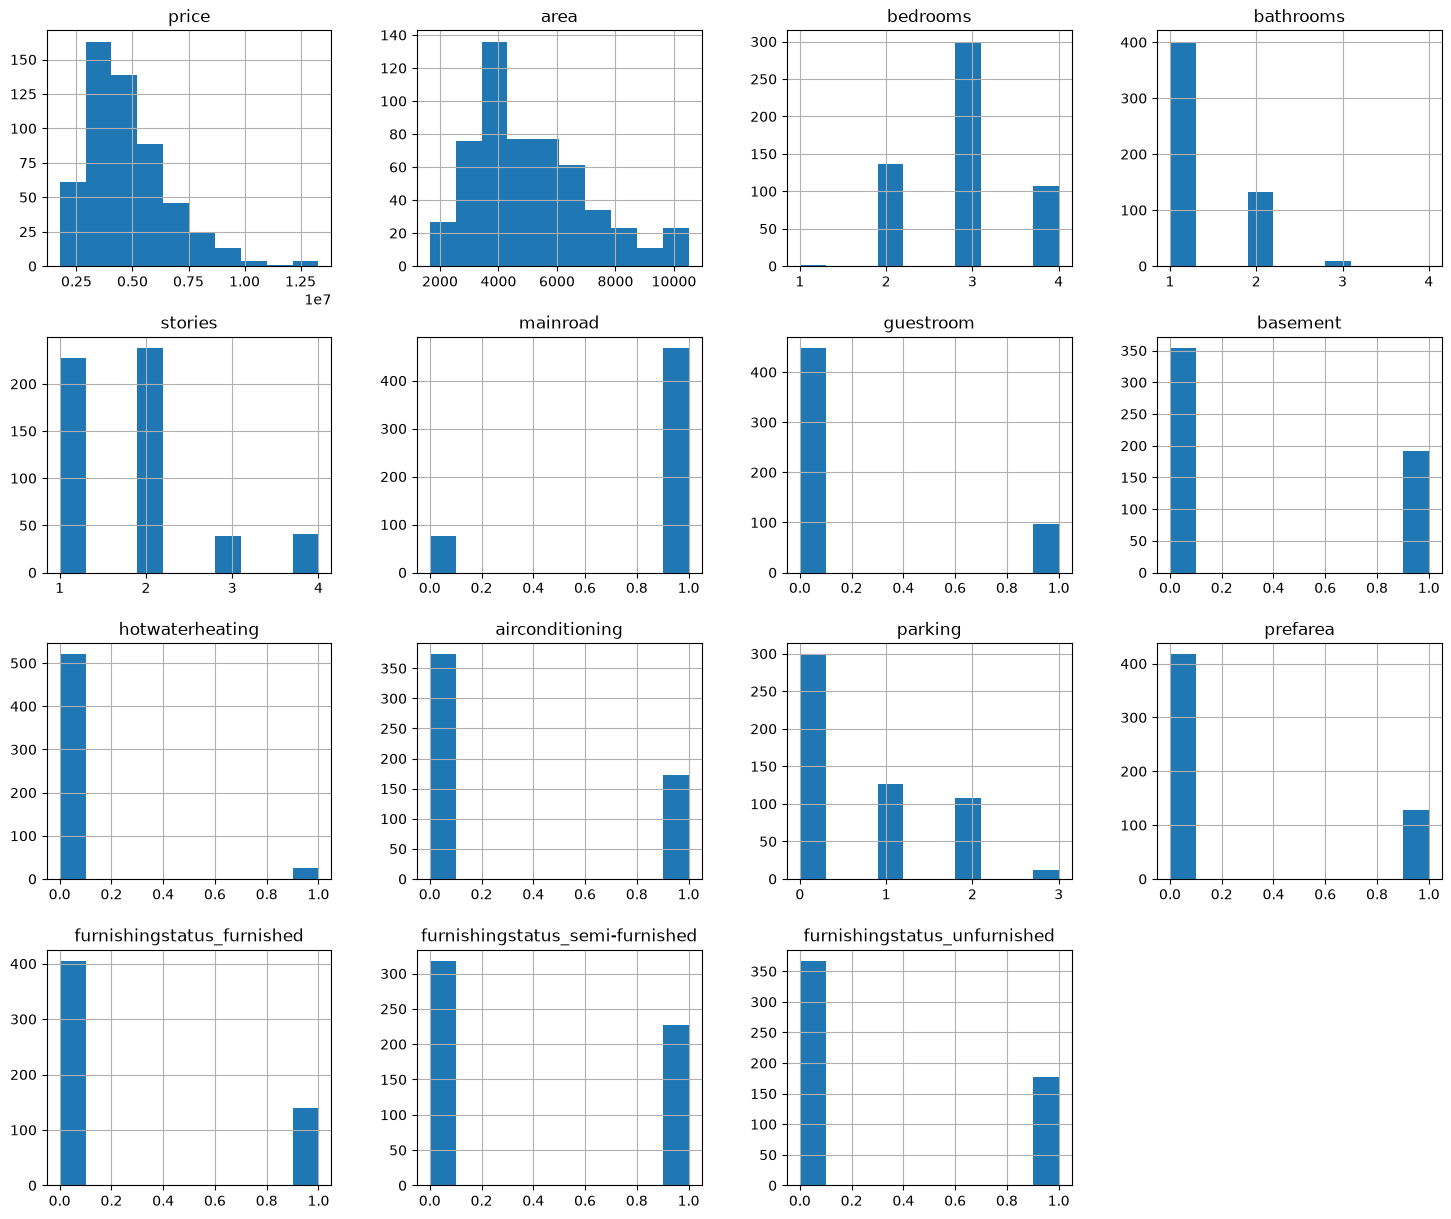

In [8]:

df.hist(figsize=(18,15))
plt.show()

In [15]:

# Lets build linear regression from scratch 

# seperate the feature and targets 
features = df.drop('price', axis=1)
targets = df['price']

# preparing the training set 
def prepare_training_data(features, targets, test_size=0.2, random_seed=None):
    if random_seed is not None:
        random.seed(random_seed)

    n_samples = len(features)
    indices = list(range(n_samples))
    random.shuffle(indices)

    split_index = int(n_samples * (1 - test_size))

    train_indices = indices[:split_index]
    test_indices = indices[split_index:]

    X_train = features.iloc[train_indices].to_numpy()
    X_test = features.iloc[test_indices].to_numpy()

    y_train = targets.iloc[train_indices].to_numpy()
    y_test = targets.iloc[test_indices].to_numpy()

    return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = prepare_training_data(features,targets)


In [58]:

# look at the training data 
print(f'Features: {X_train[0]} Target: {y_train[0]}')
print(f'Features: {X_train[1]} Target: {y_train[1]}')
print(f'Features: {X_train[2]} Target: {y_train[2]}')
print(f'Features: {X_train[3]} Target: {y_train[3]}')
print(f'Features: {X_train[4]} Target: {y_train[4]}')
print(f'Features: {X_train[5]} Target: {y_train[5]}')
print(f'Features: {X_train[6]} Target: {y_train[6]}')

Features: [3760    3    1    2    1    0    0    1    0    2    0    0    1    0] Target: 6510000
Features: [3460    4    1    2    1    0    0    0    1    0    0    0    1    0] Target: 4007500
Features: [3480    4    1    2    0    0    0    0    0    1    0    0    1    0] Target: 3290000
Features: [8960    4    4    4    1    0    0    0    1    3    0    1    0    0] Target: 12250000
Features: [6360    3    1    3    1    0    0    0    0    0    1    0    1    0] Target: 5600000
Features: [6000    2    1    1    1    0    0    0    0    0    0    0    1    0] Target: 2870000
Features: [8400    2    1    1    1    0    0    0    0    1    0    1    0    0] Target: 3780000


# function explanations
train_model function take two arguments which is X_train, y_train, so we have to split the dataset first then we need to give it to the train_model function.

## theta numpy arrays, 
theta[0] - is for theta 0 which bias
theta[1] - theta[14] - for features it is weight of the features




In [129]:
# start the training from here this is what we expect from the model at initializations
theta = np.zeros(15)
predictions = list([])
errors = list([])
    
    # first features with it output 
    # print(f'Features: {X_train[0]} Target: {y_train[0]}')
    # Features: [3760    3    1    2    1    0    0    1    0    2    0    0    1    0] Target: 6510000

for i in range(len(X_train)):
    predictions.append(np.dot(theta[1:], X_train[i]) + theta[0])
    errors.append(np.sum(predictions[i]) - y_train[i])


predictions_ = list([])
errors_ = list([])
    
    
for i in range(len(predictions)):
    predictions_.append(int(predictions[i]))
    
for i in range(len(errors)):
    errors_.append(int(errors[i]))

print("Predictions:\n", predictions_)
print("\nErrors:\n",errors_)
    


Predictions:
 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0

In [ ]:

# from now at this point we have to 15 gradiants 1 bias + 14 weights for getting the actual prediction into the linear regression in machine learning

def to_INT(predictions, errors):
    # temporary list to convert the float values to int 
    predictions_ = list([])
    errors_ = list([])
        
    for i in range(len(predictions)):
        predictions_.append(int(predictions[i]))
        
    for i in range(len(errors)):
        errors_.append(int(errors[i]))
    
    # print("Predictions:\n", predictions_)
    # print("\nErrors:\n",errors_)
    return predictions_

    
def train_model(X, y):
    theta = np.zeros(15)
    predictions = list([])
    errors = list([])

    # calculating predictions and errors for each training example.
    for i in range(len(X)):
        predictions.append(np.dot(theta[1:], X[i]) + theta[0])
        errors.append(np.sum(predictions[i]) - y[i])

    # convert to the readable integer format 
    y_predict = to_INT(predictions, errors)
    # return the y_predict
    return  y_predict

# the gradiant decent is used to reduce the cost function J.
def calc_cost(y_predict, y_actual):
    # total_error = 0
    # costs = list([])
    # total_cost = 0
    # for i in range(len(y_actual)):
    #     costs.append((y_predict[i] - y_actual[i]) ** 2)

    # total_cost = np.sum(costs)
    # print(costs)
    # print("\n", total_cost)
    # print(total_cost / (2 * len(y_actual)))

    # using Numpy 
    m = len(y_actual)
    cost = np.sum((y_predict - y_actual)**2) / (2 * m)
    return cost 
        

y_predict = train_model(X_train, y_train)
intial_cost = calc_cost(y_predict, y_train)
print("intial cost for the gradiant decent is :", intial_cost)

13294812561576.834
